# Airline Passenger Satisfaction – Data Visualization

This notebook presents visual insights into passenger demographics,
travel characteristics, flight delays, airline service quality,
and overall customer satisfaction.

All visualizations are designed to identify meaningful patterns
and support data-driven business decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
df = pd.read_csv("../data/processed/cleaned_airline_data.csv")

df.head()

,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,ease_of_online_booking,...,on-board_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,in-flight_service,in-flight_wifi_service,in-flight_entertainment,baggage_handling,satisfaction
0,Male,48,First-time,Business,Business,821,2,5.0,3,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,Female,35,Returning,Business,Business,821,26,39.0,2,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,Male,41,Returning,Business,Business,853,0,0.0,4,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,Male,50,Returning,Business,Business,1905,0,0.0,2,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,Female,49,Returning,Business,Business,3470,0,1.0,3,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [3]:
os.makedirs("../figures", exist_ok=True)

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 12

In [5]:
age_bins = [0, 25, 35, 45, 55, 65, 100]

age_labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels
)

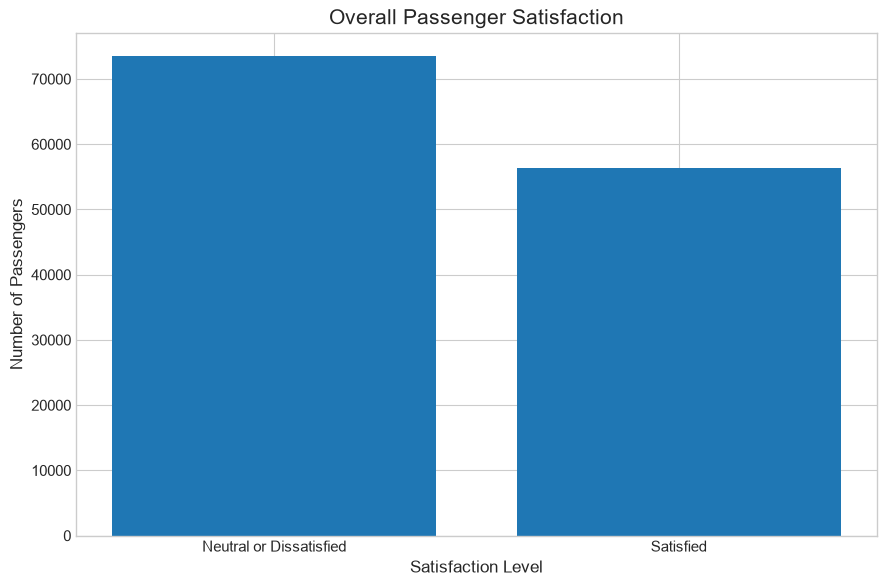

In [6]:
satisfaction_counts = df["satisfaction"].value_counts()

plt.figure(figsize=(9, 6))

plt.bar(
    satisfaction_counts.index,
    satisfaction_counts.values
)

plt.title("Overall Passenger Satisfaction")
plt.xlabel("Satisfaction Level")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig("../figures/01_overall_satisfaction.png", bbox_inches="tight")

plt.show()

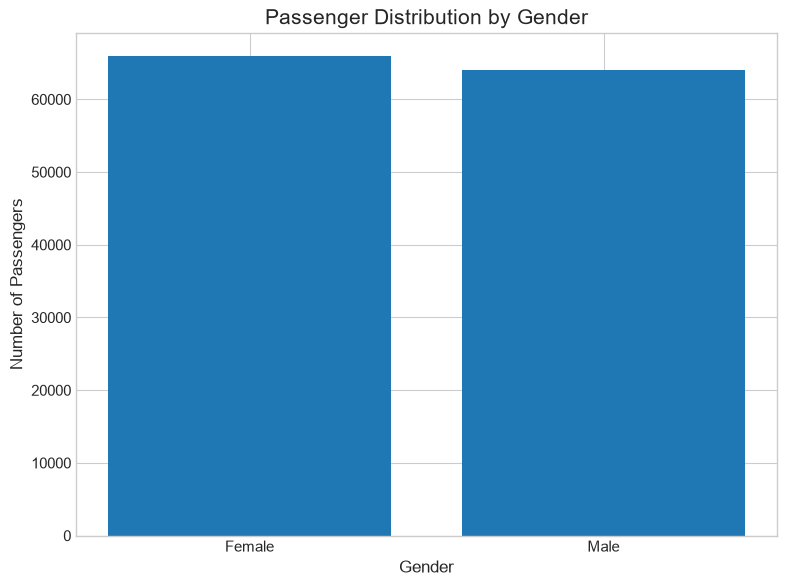

In [7]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(8, 6))

plt.bar(
    gender_counts.index,
    gender_counts.values
)

plt.title("Passenger Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig("../figures/02_gender_distribution.png", bbox_inches="tight")

plt.show()

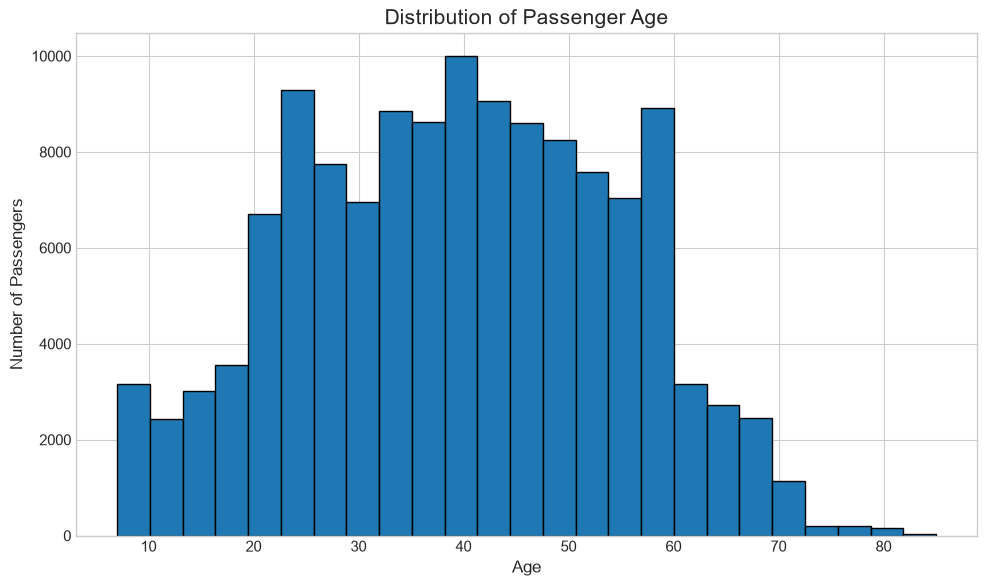

In [8]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["age"].dropna(),
    bins=25,
    edgecolor="black"
)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig("../figures/03_age_distribution.png", bbox_inches="tight")

plt.show()

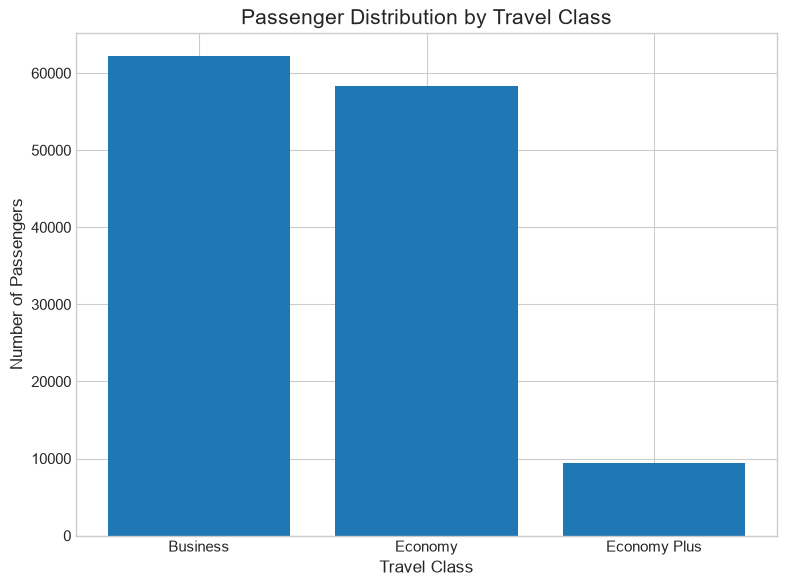

In [9]:
class_counts = df["class"].value_counts()

plt.figure(figsize=(8, 6))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Passenger Distribution by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig("../figures/04_travel_class_distribution.png", bbox_inches="tight")

plt.show()

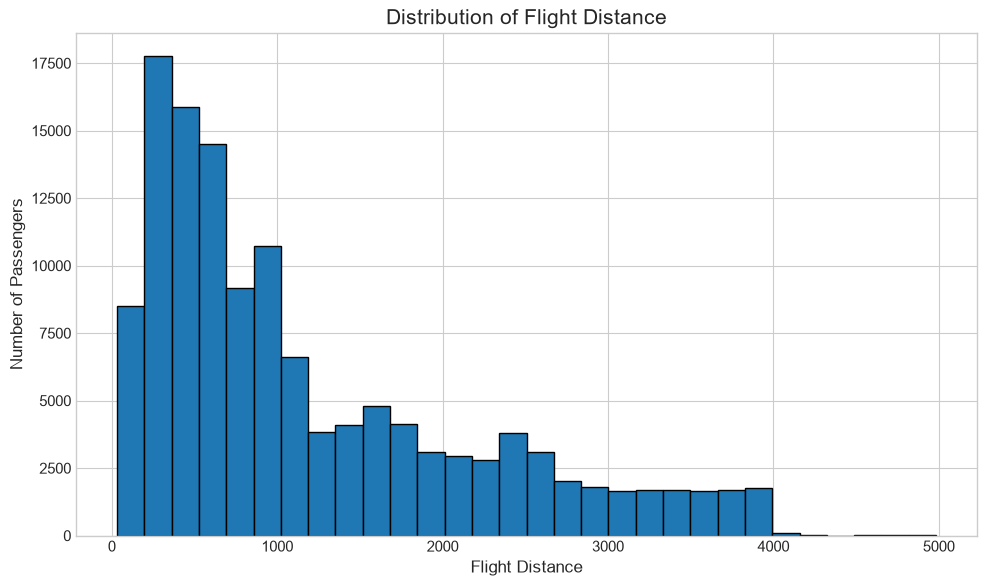

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["flight_distance"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Flight Distance")
plt.xlabel("Flight Distance")
plt.ylabel("Number of Passengers")

plt.tight_layout()

plt.savefig("../figures/05_flight_distance_distribution.png", bbox_inches="tight")

plt.show()

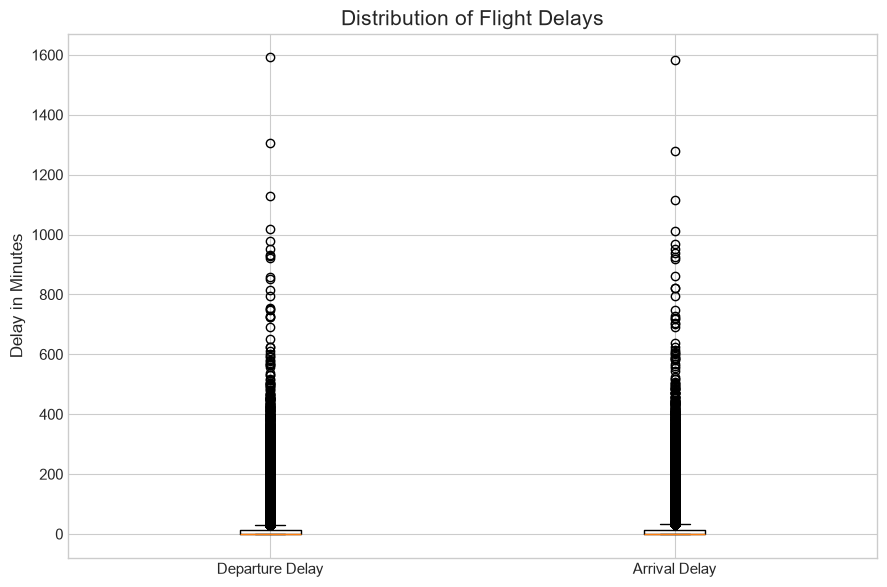

In [11]:
delay_data = [
    df["departure_delay"].dropna(),
    df["arrival_delay"].dropna()
]

plt.figure(figsize=(9, 6))

plt.boxplot(
    delay_data,
    tick_labels=["Departure Delay", "Arrival Delay"]
)

plt.title("Distribution of Flight Delays")
plt.ylabel("Delay in Minutes")

plt.tight_layout()

plt.savefig("../figures/06_flight_delays.png", bbox_inches="tight")

plt.show()

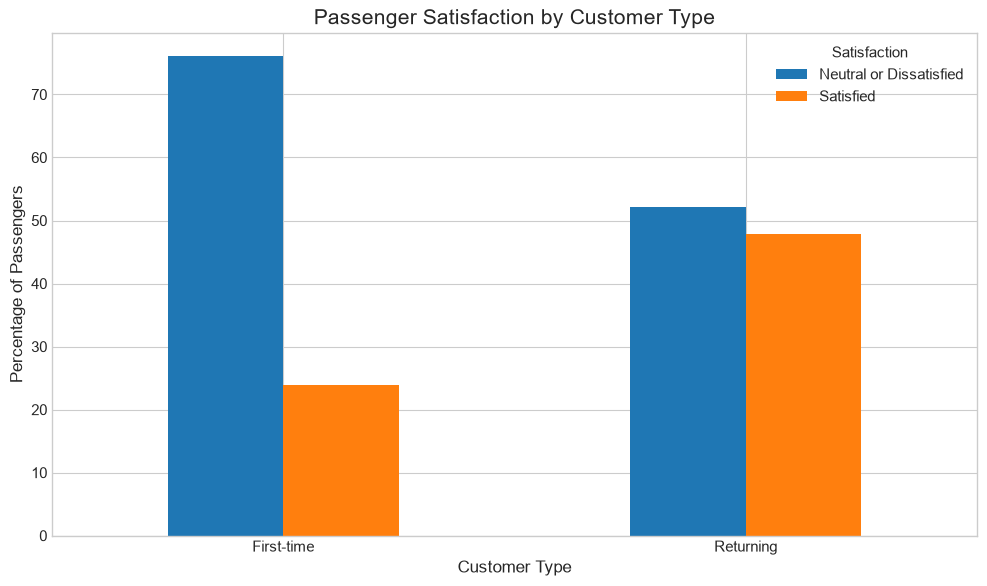

In [12]:
customer_satisfaction = pd.crosstab(
    df["customer_type"],
    df["satisfaction"],
    normalize="index"
) * 100

customer_satisfaction.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Passenger Satisfaction by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")

plt.tight_layout()

plt.savefig("../figures/07_satisfaction_by_customer_type.png", bbox_inches="tight")

plt.show()

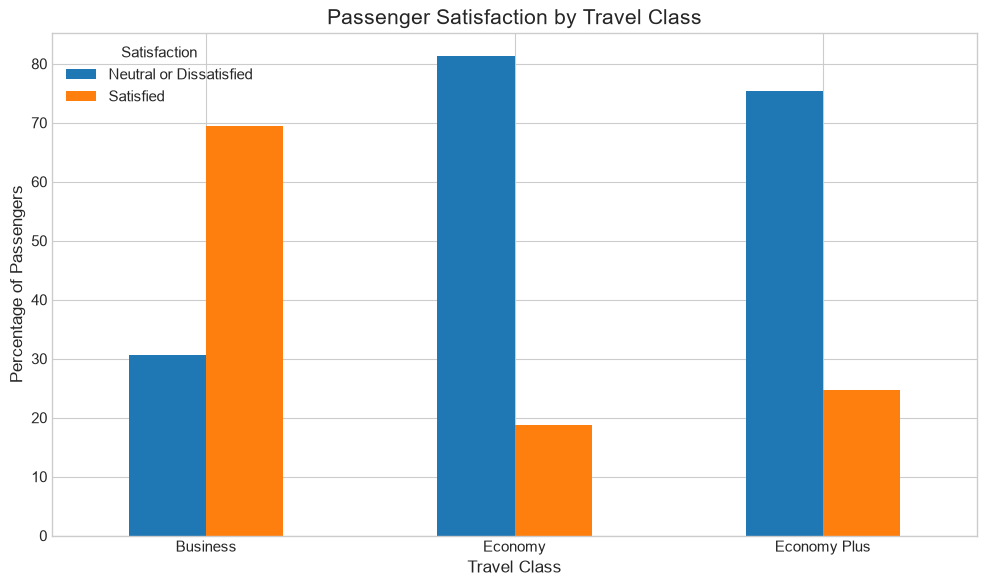

In [13]:
class_satisfaction = pd.crosstab(
    df["class"],
    df["satisfaction"],
    normalize="index"
) * 100

class_satisfaction.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Passenger Satisfaction by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")

plt.tight_layout()

plt.savefig("../figures/08_satisfaction_by_class.png", bbox_inches="tight")

plt.show()

In [19]:
service_columns = [
    "departure_and_arrival_time_convenience",
    "ease_of_online_booking",
    "check-in_service",
    "online_boarding",
    "gate_location",
    "on-board_service",
    "seat_comfort",
    "leg_room_service",
    "cleanliness",
    "food_and_drink",
    "in-flight_service",
    "in-flight_wifi_service",
    "in-flight_entertainment",
    "baggage_handling"
]

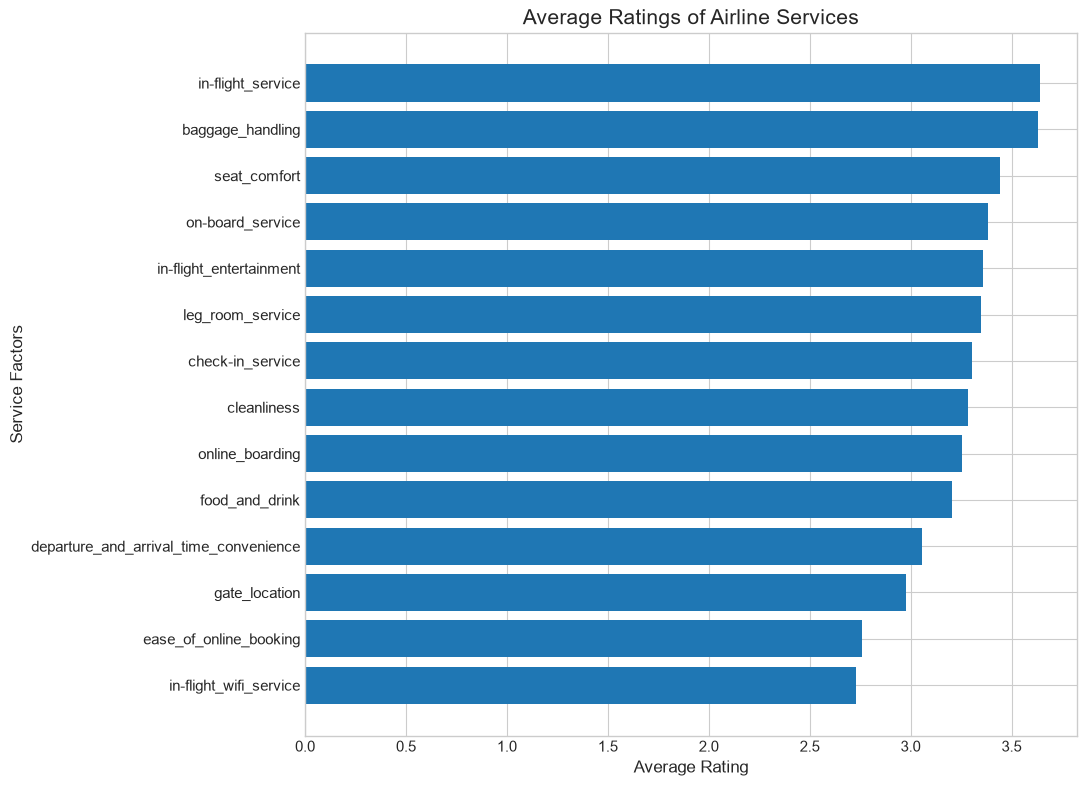

In [20]:
service_ratings = df[service_columns].mean().sort_values()

plt.figure(figsize=(11, 8))

plt.barh(
    service_ratings.index,
    service_ratings.values
)

plt.title("Average Ratings of Airline Services")
plt.xlabel("Average Rating")
plt.ylabel("Service Factors")

plt.tight_layout()

plt.savefig("../figures/09_average_service_ratings.png", bbox_inches="tight")

plt.show()

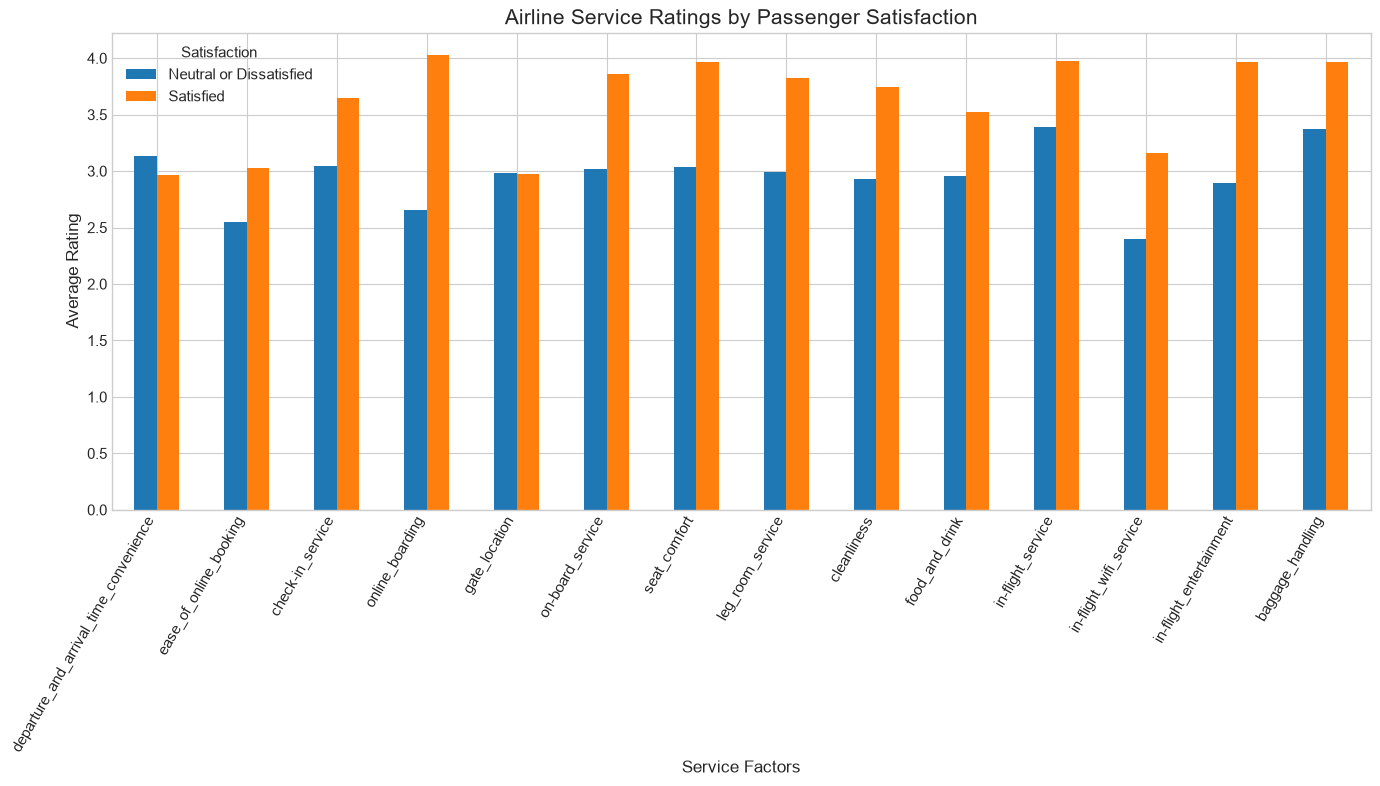

In [21]:
service_by_satisfaction = df.groupby("satisfaction")[service_columns].mean().T

service_by_satisfaction.plot(
    kind="bar",
    figsize=(14, 8)
)

plt.title("Airline Service Ratings by Passenger Satisfaction")
plt.xlabel("Service Factors")
plt.ylabel("Average Rating")
plt.xticks(rotation=60, ha="right")
plt.legend(title="Satisfaction")

plt.tight_layout()

plt.savefig("../figures/10_service_ratings_by_satisfaction.png", bbox_inches="tight")

plt.show()